# Three flow-based TPP models

This notebook compares three marked event-time models on the same clinical cohort. **A uses a fixed baseline vector; B adds dynamic feature modelling; C restricts which current feature latents enter the timing/mark branch.** All three predict both **when** the next visit happens and **what type** of visit it is.

## Shared notation and likelihood

At an observed visit origin \(t_n\), let:

- \(s\): the patient's baseline context, held fixed throughout the sequence. Baseline employment or marital status can be included here; “fixed” describes how A uses them, not whether they can change in real life.
- \(\tau_{n+1}=t_{n+1}-t_n\): the next inter-arrival time (IAT).
- \(m_{n+1}\): the next visit's mark: outpatient, emergency or inpatient.
- \(x_n\): the latest observed continuous physiological state (standardised BP, glucose and creatinine).
- \(q_n\): baseline context plus other currently available information, such as recorded employment/marital status, age, missingness, staleness and the previous visit type.
- \(H_n\): the causal history summary used by the relevant model. Only information available by \(t_n\) may enter the next-event forecast.

### Deriving a mark-conditioned timing model

We want the next waiting-time distribution to depend on whether the next visit is outpatient, emergency or inpatient. For a fixed history, those visit types should be allowed to have different timing distributions. **We choose to predict the mark first and condition timing on it.** This is a chain-rule factorisation, not a timing–mark independence assumption:

\[
\boxed{p(\tau_{n+1},m_{n+1}=k\mid c_n)
=\underbrace{p(m_{n+1}=k\mid c_n)}_{\pi_k(c_n)}
\underbrace{p(\tau_{n+1}\mid m_{n+1}=k,c_n)}_{f_k(\tau_{n+1}\mid c_n)}.}
\]

“Mark first” describes the generative sampling order, not that we know a future visit's type when making a forecast. For a forecast without a known mark—and for right censoring—we must account for **all possible types**. Let's derive the pieces.

**1. Predict the mark and its conditional waiting time.** Each model builds its own context \(c_n\). One network outputs mark logits and a separate set of flow parameters for each of the three marks:

\[
\pi_k(c_n)=\operatorname{softmax}(g_\theta(c_n))_k,
\qquad
z^\tau_{n+1}=F_{\tau,k,\theta}(\tau_{n+1};c_n)
\sim\mathcal N(0,1).
\]

The change-of-variables formula then converts the normal density into a mark-conditioned waiting-time density:

\[
f_k(\tau\mid c_n)
=\phi\!\left(F_{\tau,k,\theta}(\tau;c_n)\right)
\left|\frac{\partial F_{\tau,k,\theta}(\tau;c_n)}{\partial\tau}\right|.
\]

The flow is increasing in \(\tau\). Thus its conditional survival is

\[
S_k(\tau\mid c_n)
=P(T>\tau\mid m=k,c_n)
=1-\Phi\!\left(F_{\tau,k,\theta}(\tau;c_n)\right),
\]

where \(\phi\) and \(\Phi\) are the standard normal density and CDF. Sharing the conditioning network does not force the three flows to be identical.

**2. Forecast without knowing the next mark.** Sum the joint density over marks:

\[
f(\tau\mid c_n)=\sum_k\pi_k(c_n)f_k(\tau\mid c_n),
\qquad
S(\tau\mid c_n)=\sum_k\pi_k(c_n)S_k(\tau\mid c_n).
\]

These are a **mixture density and mixture survival**, not one common timing distribution multiplied by three probabilities. The total and type-specific intensities are

\[
\lambda(t_n+\tau\mid c_n)=h(\tau\mid c_n)
=\frac{\sum_k\pi_k(c_n)f_k(\tau\mid c_n)}{S(\tau\mid c_n)},
\qquad
\lambda_k(t_n+\tau\mid c_n)
=\frac{\pi_k(c_n)f_k(\tau\mid c_n)}{S(\tau\mid c_n)}.
\]

The denominator is the survival of **any next event**, so \(\sum_k\lambda_k=\lambda\). Multiplying \(\pi_k\) by the component hazard \(f_k/S_k\) would give the wrong type-specific intensity.

**3. Train on observed events and right censoring.** An observed visit supplies both its waiting time and its mark, so its log-likelihood is \(\log\pi_k+\log f_k\). At the end of follow-up we know only that no visit has occurred yet, not what its eventual type will be. Therefore censoring contributes the **mixture** survival:

\[
\boxed{\ell_{\mathrm{events}}
=\sum_{n=0}^{N-1}\left[
\log\pi_{m_{n+1}}(c_n)
+\log f_{m_{n+1}}(\tau_{n+1}\mid c_n)\right]
+\log\!\left[\sum_k\pi_k(c_N)S_k(C-t_N\mid c_N)\right].}
\]

Here \(t_0\) is the chosen observation origin and \(C\) is the end of follow-up. If no visits are observed, only the mixture survival from \(t_0\) to \(C\) remains. There is no observed mark to select in a censored interval. The implementation evaluates the mixture sums in log space for numerical stability.

**4. Update predictions after waiting.** If we have already waited \(a\) without a visit, the eventual-type probabilities become

\[
w_k(a)=P(m=k\mid T>a,c_n)
=\frac{\pi_k(c_n)S_k(a\mid c_n)}{S(a\mid c_n)}.
\]

The remaining waiting time \(R=T-a\) has survival \(P(R>r\mid T>a,c_n)=S(a+r\mid c_n)/S(a\mid c_n)\). To sample consistently, draw a mark with weights \(w_k(a)\), then draw its waiting time conditional on \(T>a\) and subtract \(a\). At a newly observed event origin, \(a=0\), so the weights reduce to \(\pi_k\). If a visit occurs at a specified waiting time, its type probabilities instead use

\[
P(m=k\mid T=\tau,c_n)
=\frac{\pi_k(c_n)f_k(\tau\mid c_n)}{f(\tau\mid c_n)}.
\]

All three models use these same timing, mark and censoring calculations. Their distinction is how they construct \(c_n\) and whether they also learn a density for dynamic feature snapshots.

## TPP-A: conditional timing and marks from a fixed baseline

A causal Transformer summarises previous IATs and elapsed-time information into a timing-history state:

\[
H_n^\tau=E_\psi(\tau_1,\ldots,\tau_n).
\]

We concatenate this state with the patient's fixed baseline vector to construct the context:

\[
c_n^A=[s,H_n^\tau].
\]

From this context, the network predicts the next mark probabilities and the waiting-time distribution conditional on each mark:

\[
p_A(\tau_{n+1},m_{n+1}=k\mid s,\tau_{1:n})
=\pi_k^A(c_n^A)\,f_{A,k}(\tau_{n+1}\mid c_n^A).
\]

Training uses the observed timing/mark terms and the final right-censoring term derived above:

\[
\ell_A=\ell_{\mathrm{events}}^A.
\]

The baseline vector stays fixed: A does not consume subsequent covariate updates or assign a density to physiology. It learns timing and mark probabilities only.

## TPP-B: dynamic feature density, then timing and marks

At each origin, an invertible feature flow transforms the currently available physiological state into normal latent coordinates, conditional on earlier feature history:

\[
z_n^x=F_{x,\theta}(x_n;H^x_{n-1}),
\qquad z_n^x\sim\mathcal N(0,I).
\]

The change-of-variables formula gives the physiological snapshot's density. Here \(\phi_3\) is the three-dimensional standard normal density:

\[
p_B(x_n\mid H^x_{n-1})
=\phi_3(z_n^x)\left|\det\frac{\partial F_{x,\theta}}{\partial x_n}\right|.
\]

We combine all current physiology latents, the available covariates and the timing-history state into the next-event context:

\[
c_n^B=[z_n^x,q_n,H_n^\tau].
\]

The feature-history state summarises earlier observed physiological snapshots; the timing-history state summarises earlier dynamic snapshots and gaps. Unlike A, B uses changing covariates and physiology. Categorical covariates, masks and staleness are conditioning inputs, not continuous flow targets.

The joint density combines the snapshot density with the mark probability and its conditional waiting-time density:

\[
p_B(x_n,\tau_{n+1},m_{n+1}=k\mid\text{past},q_n)
=p_B(x_n\mid H^x_{n-1})\,\pi_k^B(c_n^B)\,
f_{B,k}(\tau_{n+1}\mid c_n^B).
\]

Training therefore adds the feature-snapshot log densities to the event and censoring log-likelihood:

\[
\ell_B=\ell_{\mathrm{events}}^B
+\sum_{n=0}^{N}\log p_B(x_n\mid H^x_{n-1}).
\]

Learning this additional density also allows B to generate feature snapshots by sampling normal latents and inverting the feature flow.

## TPP-C: the same dynamic feature density, with shared/private latents

C keeps the complete feature transformation invertible, but partitions its output into shared coordinates \(u_n\) and private coordinates \(r_n\):

\[
F_{x,\theta}(x_n;H^x_{n-1})=(u_n,r_n).
\]

Only the current shared coordinates enter the timing/mark context directly (`use_private=False`), alongside covariates and causal timing history:

\[
c_n^C=[u_n,q_n,H_n^\tau].
\]

Both shared and private coordinates remain necessary for the full feature density and for inversion:

\[
p_C(x_n\mid H^x_{n-1})
=\phi_3([u_n,r_n])
\left|\det\frac{\partial F_{x,\theta}}{\partial x_n}\right|.
\]

We combine that complete feature density with the next-event prediction made from the restricted context:

\[
p_C(x_n,\tau_{n+1},m_{n+1}=k\mid\text{past},q_n)
=p_C(x_n\mid H^x_{n-1})\,\pi_k^C(c_n^C)\,
f_{C,k}(\tau_{n+1}\mid c_n^C).
\]

As in B, training includes both the event/censoring terms and the feature-snapshot log densities:

\[
\ell_C=\ell_{\mathrm{events}}^C
+\sum_{n=0}^{N}\log p_C(x_n\mid H^x_{n-1}).
\]

In this notebook there are two shared coordinates and one private coordinate. This restriction applies to transformed physiology: other covariates \(q_n\) and causal history still enter the event branch. It does not establish causal or statistically independent biological factors.

## Comparing the incremental complexity

| Aspect | TPP-A | TPP-B | TPP-C |
|---|---|---|---|
| Patient covariates | Fixed baseline \(s\) | Current dynamic context \(q_n\) | Current dynamic context \(q_n\) |
| History encoder | Causal Transformer over IATs | Feature and timing causal Transformer states | Feature and timing causal Transformer states |
| Current physiology | Not used | All feature latents \(z_n^x\) | Shared feature latents \(u_n\) in timing/marks |
| Feature flow | None | Invertible flow for \(x_n\) | Same, with \((u_n,r_n)\) split |
| Next-event prediction | Mark-conditioned timing mixture + mark probabilities | Mark-conditioned timing mixture + mark probabilities | Mark-conditioned timing mixture + mark probabilities |
| Training objective | Event/mark likelihood + censoring | A's types of terms + feature density | B's types of terms + restricted latent routing |
| Additional inference | None for physiology | Continuous feature-state sampling | Feature sampling + shared/private decomposition |
| Main added complexity | Conditional timing flow | Dynamic inputs and a feature-density objective | A restriction on B's latent inputs, rather than an additional density factor |

**How “dynamic” works here:** B/C refresh context at visit origins. A measurement or covariate update between visits is included when the next snapshot is built; it does not immediately refresh the intensity in the middle of that interval. The next-IAT flow's parameters stay fixed within each interval, while its hazard still varies with elapsed time. B/C begin at the first complete physiological snapshot, so their windows can start later than A's; raw likelihood scores are not directly comparable across these different windows or objectives. Carried-forward feature snapshots are not a GP trajectory or a likelihood for the complete irregular measurement process.

We will now fit each model, inspect its event-time fit over one patient's observation window, and make a next-event forecast. For background on marked point-process likelihoods, see [Rasmussen's lecture notes](https://arxiv.org/abs/1806.00221).

**Clinical input encoding used throughout these models.** Categories use small learned embeddings: sex, employment, record kind and event type use two coordinates; marital status and history-variable identity use three, while GP query-output identity uses two. Missing/unseen categories are explicit. A category that does not apply to a token uses a zero padding embedding. Adapter indicators are decoded to IDs before neural computation. Physiological values remain training-standardised, with explicit missingness and known-value flags. With small vocabularies, embeddings provide a compact representation; a one-hot vector followed by a linear projection already learns category vectors, so this change does not automatically improve predictions.

Age supplies a **learned continuous absolute-age encoding**, rather than a raw content feature or a sinusoidal code. A small two-layer network maps age in years into the model's hidden dimension:

\[
\mathrm{PE}_\omega(a)=W_2\tanh\!\left(W_1\frac{a}{100}+b_1\right)+b_2.
\]

History tokens add this encoding after their learned content projection. TPP-A reconstructs record ages from entry age and accumulated IATs; dynamic TPPs and GP histories use recorded ages. Equal-age records share an encoding, while the causal attention mask still prevents attending to later records. Each conditioning network replaces age scalars with learned age encodings and categorical indicators with embeddings. All encoding parameters are trained with the model. Duration/IAT inputs retain their log scaling.

The GP still uses actual age differences as its continuous covariance coordinate; output IDs select the covariance matrix. Its neural mean, feature maps and flows receive learned age and output embeddings. This removes imposed periodicity, but does not guarantee reliable extrapolation or a biologically correct ageing trajectory.

In [1]:
from pathlib import Path
import torch
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
from lifetime_clinical.tutorials.experiments import (load_toy,tpp_data,fit_tpp_a,fit_tpp_b,fit_tpp_c,representative_tpp_sequence)
from lifetime_clinical.visualization import plot_fit_history, plot_tpp_timeline_fit, plot_next_event_forecast, plot_feature_flow_fit
from lifetime_clinical.visualization.tpp import forecast_next_feature_snapshot, _dynamic_history
from lifetime_clinical.data.tutorial import physiology_feature_indices, context_feature_names
from lifetime_clinical.data.preprocessing import VARIABLES

In [2]:
FAST_MODE=True
EPOCHS=5 if FAST_MODE else 10
DEVICE="cuda" if torch.cuda.is_available() else "cpu"
DATA_DIR=ROOT/"data"/("toy" if FAST_MODE else "synthetic")
dataset,splits,pre=load_toy(DATA_DIR)
print("device",DEVICE,"epochs",EPOCHS,"dataset",DATA_DIR)
static_data=tpp_data(dataset,splits,pre,dynamic=False)
dynamic_data=tpp_data(dataset,splits,pre,dynamic=True)
print({k:len(v) for k,v in static_data.items()}, {k:len(v) for k,v in dynamic_data.items()})

device cpu epochs 5 dataset C:\Users\dario\Desktop\Doctorado\lifetime_clinical_tutorial\data\toy


{'train': 100, 'validation': 20, 'test': 10} {'train': 95, 'validation': 20, 'test': 10}


## TPP-A — conditional timing flow

The history encoder produces a causal state

\[
H_n=E_\psi(\mathcal H_n),
\]

and a conditional invertible flow maps the observed next IAT to a simple base variable

\[
z_{n+1}=F_{\tau,m_{n+1},\theta}(\tau_{n+1};H_n),\qquad z_{n+1}\sim\mathcal N(0,1).
\]

Thus

\[
\log p(\tau_{n+1}\mid m_{n+1},H_n)=\log p_Z(z_{n+1})+\log\left|\frac{\partial z_{n+1}}{\partial \tau_{n+1}}\right|.
\]

**Input:** static patient context + previous IATs.  
**Learns:** the full conditional distribution of the next IAT.  
**Can infer:** density, survival, hazard/intensity, quantiles and sampled next-event times.
The observed mark selects the timing flow used for this event. Add its log mark probability to obtain the joint event likelihood. Forecasts and censored tails sum over all marks, as derived in cell 1.


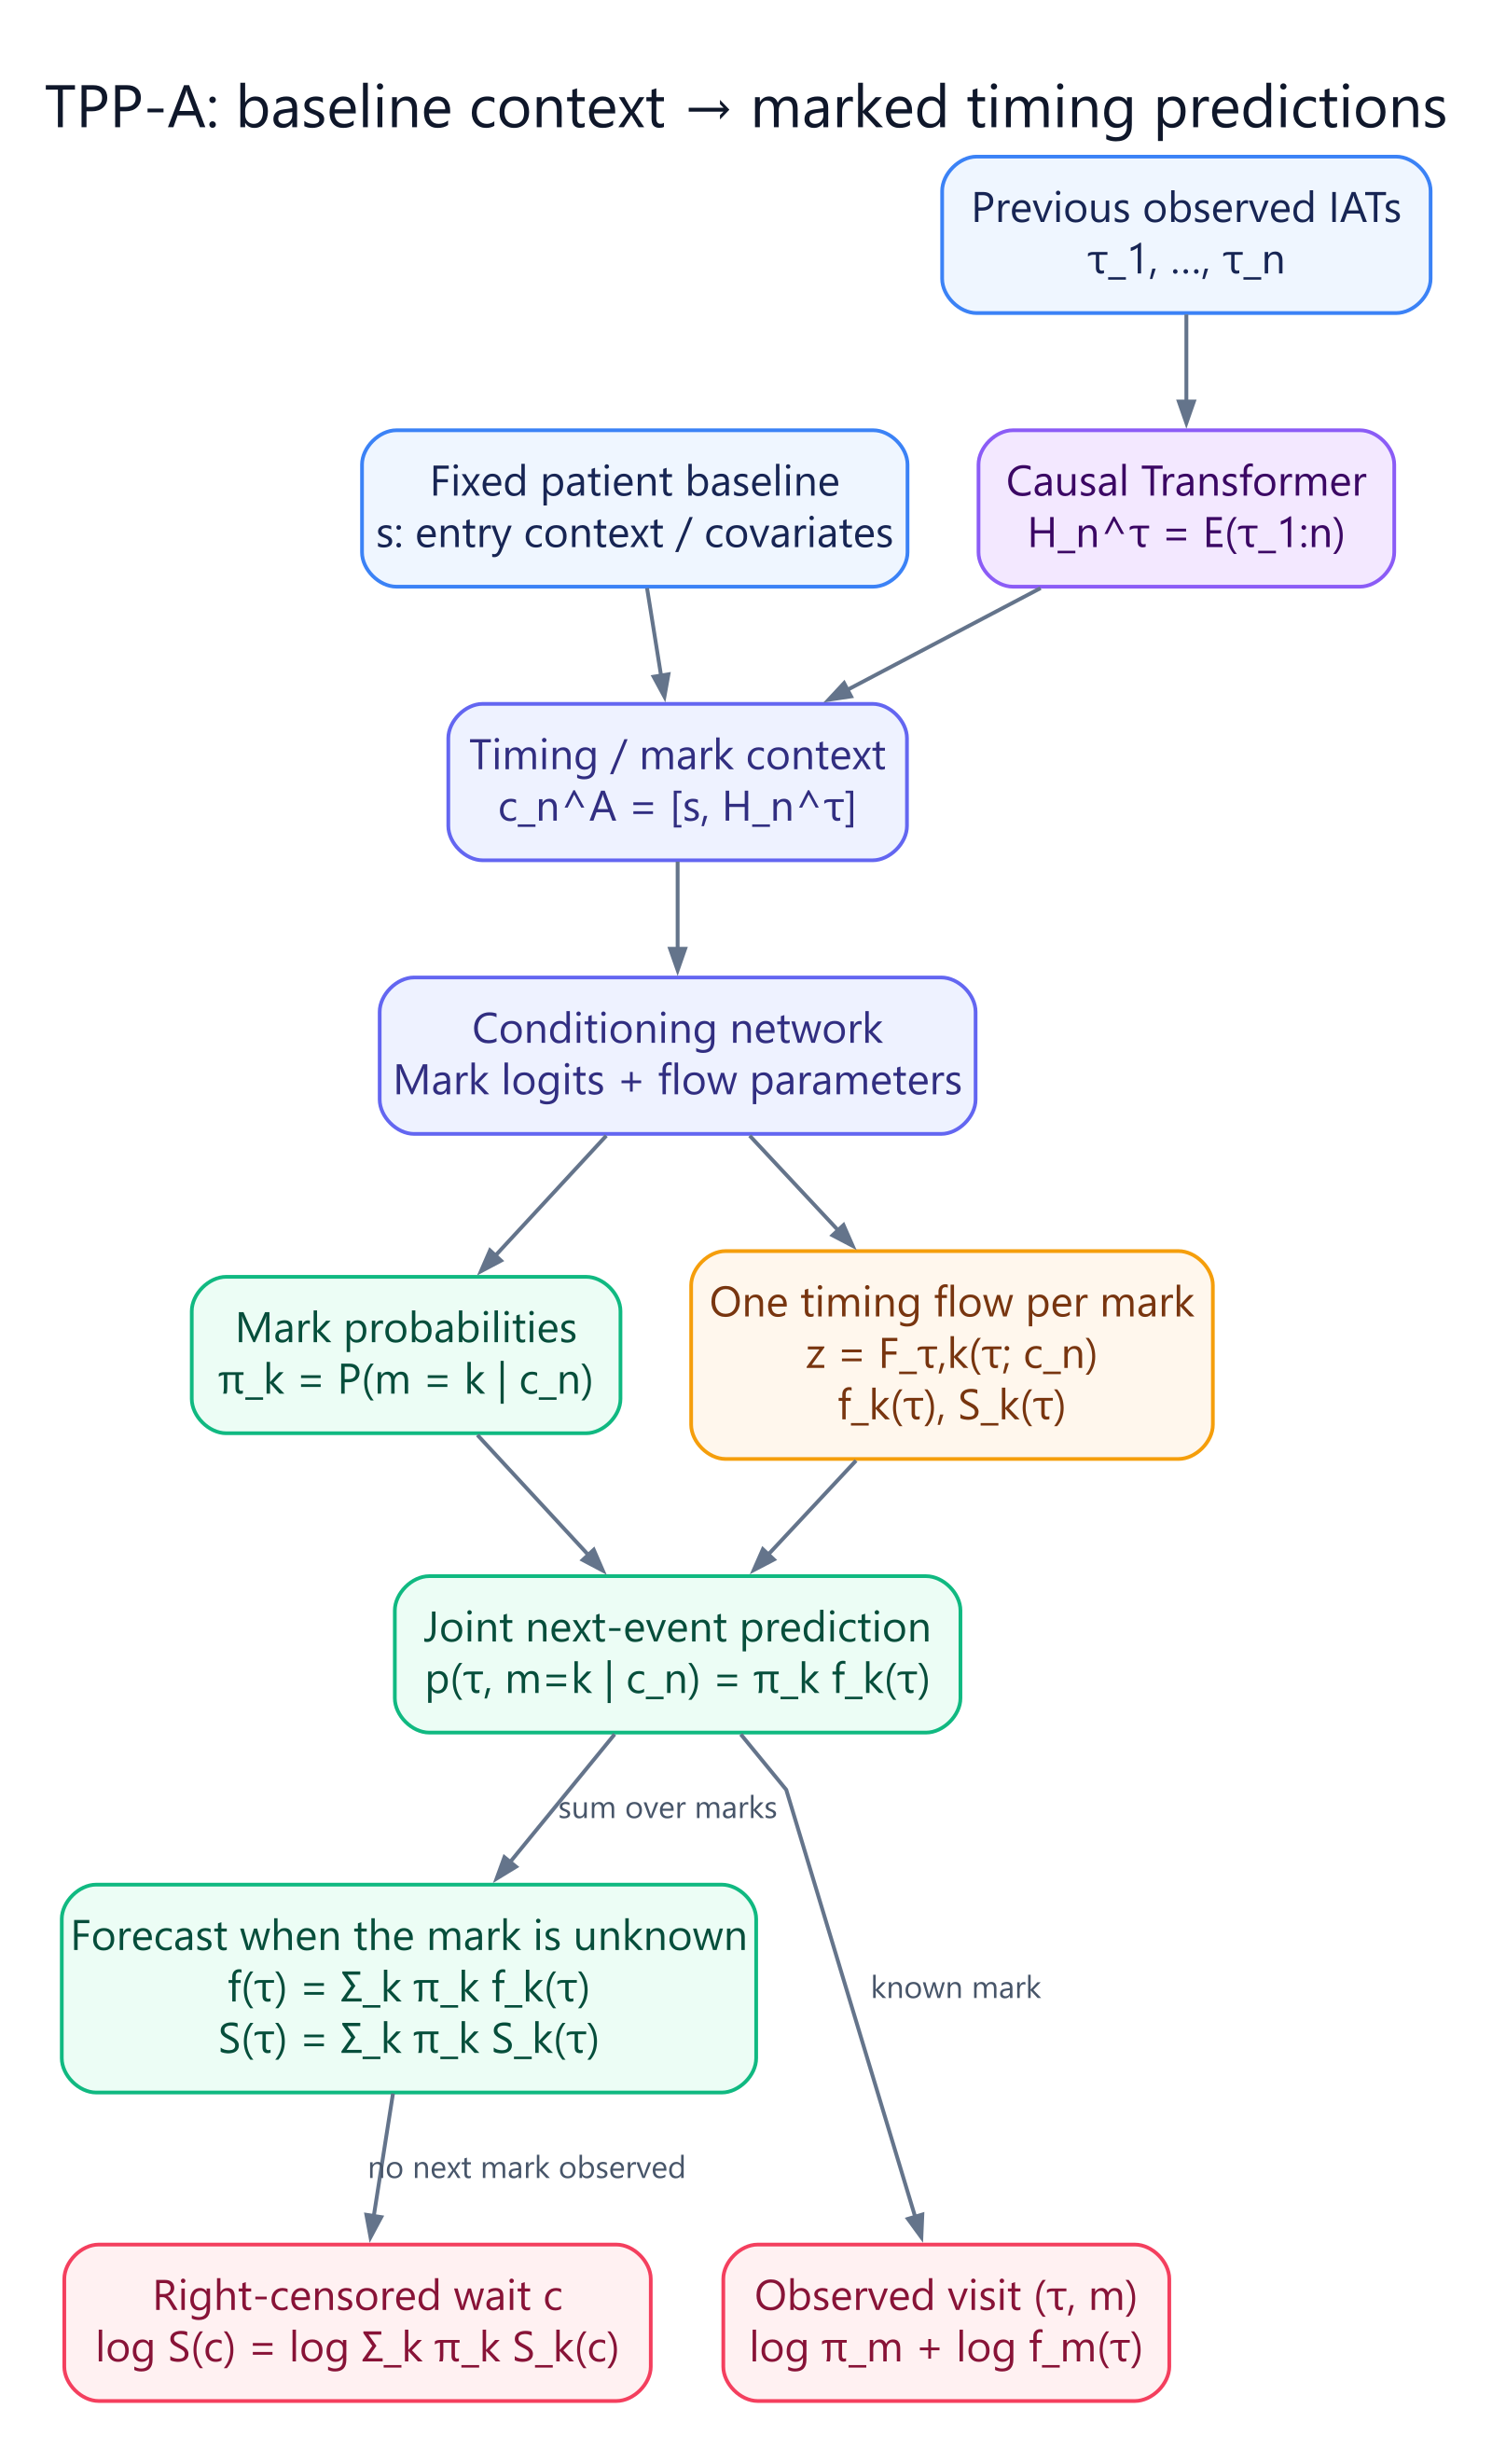

In [3]:
from IPython.display import display
import base64
# TPP-A: inputs → outputs
display({
    'image/svg+xml': (ROOT / 'diagrams/tpp_a.svg').read_text(encoding='utf-8'),
    'image/png': base64.b64encode((ROOT / 'diagrams/tpp_a.png').read_bytes()).decode('ascii'),
}, raw=True)

We now fit TPP-A and inspect its training and validation negative log-likelihood (NLL). Lower values indicate better density fit; validation NLL helps assess generalization.

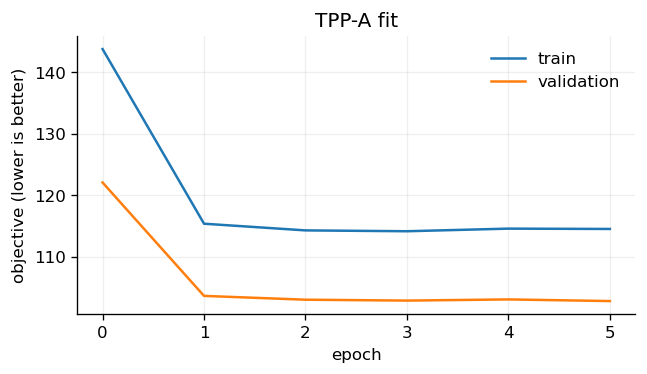

In [4]:
tpp_a=fit_tpp_a(static_data,epochs=EPOCHS,device=DEVICE)
fig,ax=plt.subplots(figsize=(6,3)); plot_fit_history(tpp_a,ax,title="TPP-A fit"); plt.show()

Let’s inspect the fitted conditional intensity along one held-out patient’s observed timeline, then forecast beyond censoring.

We are now at the right-censoring time \(t=t_C\): no further visit has been observed since the last event at \(t_n\). Let \(a=t_C-t_n\) and let \(h>0\) be time into the future. Holding the latest available context \(c_n\) fixed, we condition on having already waited \(a\):

\[
p(T_{\mathrm{next}}-t_C=h,m=k\mid T_{\mathrm{next}}>t_C,c_n)
=\frac{\pi_k(c_n)f_k(a+h\mid c_n)}{\sum_j\pi_j(c_n)S_j(a\mid c_n)}.
\]

The coloured density curves show each event type's contribution over future time; integrating a curve up to a horizon gives the probability that the **next** event has that type and occurs before that horizon. The black curve sums the types. Survival gives the probability of no next event yet, and the marked intensity curves give the instantaneous rate for each type among patients still waiting. These are next-event forecasts, rather than probabilities of every event in a simulated future trajectory.

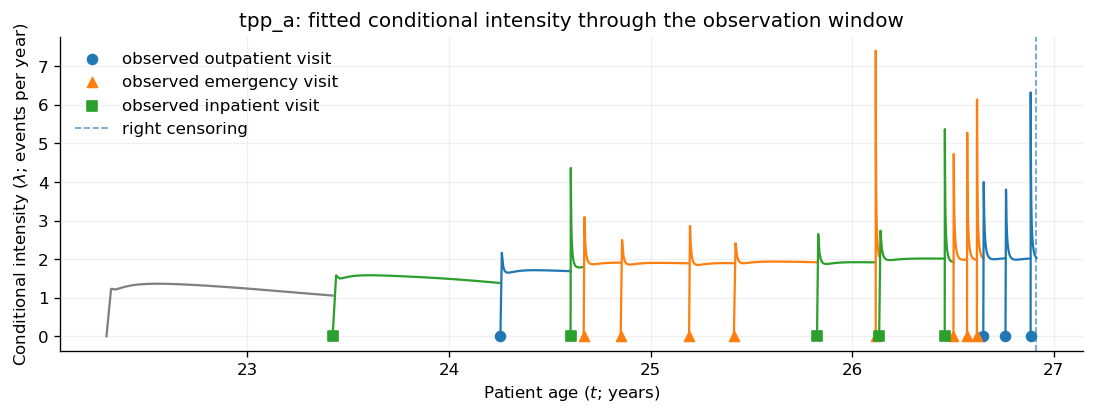

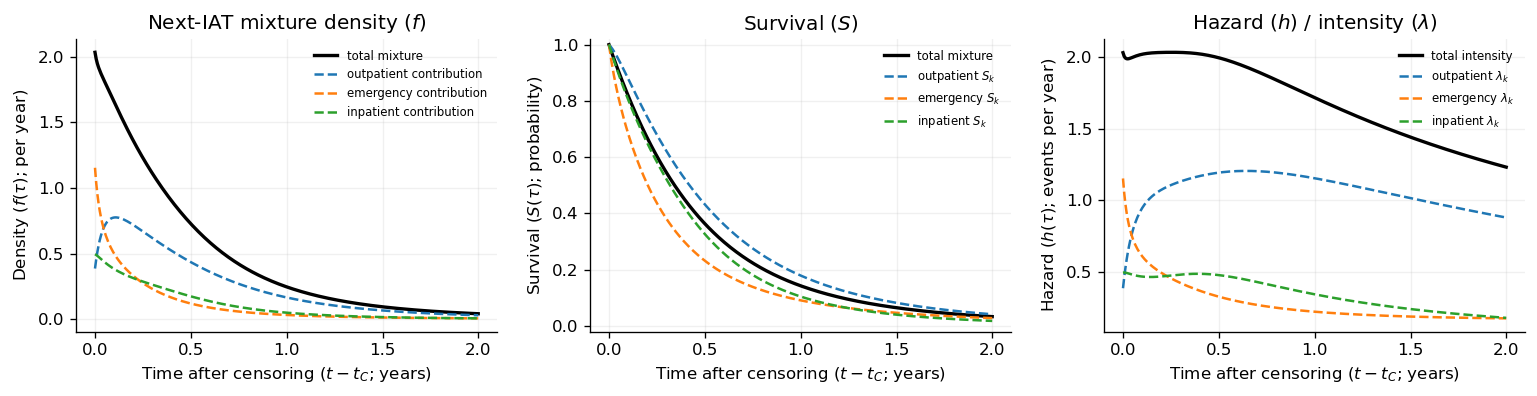

In [5]:
seq_a=representative_tpp_sequence(static_data["test"],min_events=8)
fig,ax=plt.subplots(figsize=(11,3.4)); plot_tpp_timeline_fit(tpp_a,seq_a,pre,ax=ax); plt.show()
plot_next_event_forecast(tpp_a,seq_a,pre,horizon_days=730); plt.show()

The piecewise curve is the fitted conditional point-process intensity. At each observed event, the history changes and a new conditional waiting-time distribution starts. The final dashed line is right censoring, not an event.
The next-event plots show the total mixture in black. The density contributions and type-specific intensities sum to their black curves; the coloured survival curves are mark-conditional survival functions and combine using the mark weights. Line colours on the fitted timeline identify the previous observed mark; that timeline still plots total intensity.


## TPP-B — dynamic feature flow + timing flow

TPP-B additionally assigns density to a dynamic continuous feature state. At event index \(n\),

\[
z^x_n=F_x(x_n;H^x_{n-1}),\qquad z^x_n\sim\mathcal N(0,I),
\]

then the timing flow conditions on the transformed current state,

\[
z^\tau_{n+1}=F_{\tau,m_{n+1}}(\tau_{n+1};z^x_n,H^\tau_n).
\]

The joint objective factorises as

\[
p(x_{0:N},\tau_{1:N},m_{1:N}\mid q_{0:N})
=\left[\prod_{n=0}^{N}p(x_n\mid H^x_{n-1})\right]
\left[\prod_{n=0}^{N-1}\pi_{m_{n+1}}(c_n^B)f_{B,m_{n+1}}(\tau_{n+1}\mid c_n^B)\right].
\]

**Here `x_n` is dynamic:** the latest BP, glucose and creatinine state at that point in the event timeline. Masks and staleness remain conditioning metadata rather than flow-density coordinates.
This factorisation is schematic for completed visits; the full observed-window objective also includes the mixture survival of the final censored interval. Changing categorical covariates remain conditioning inputs.


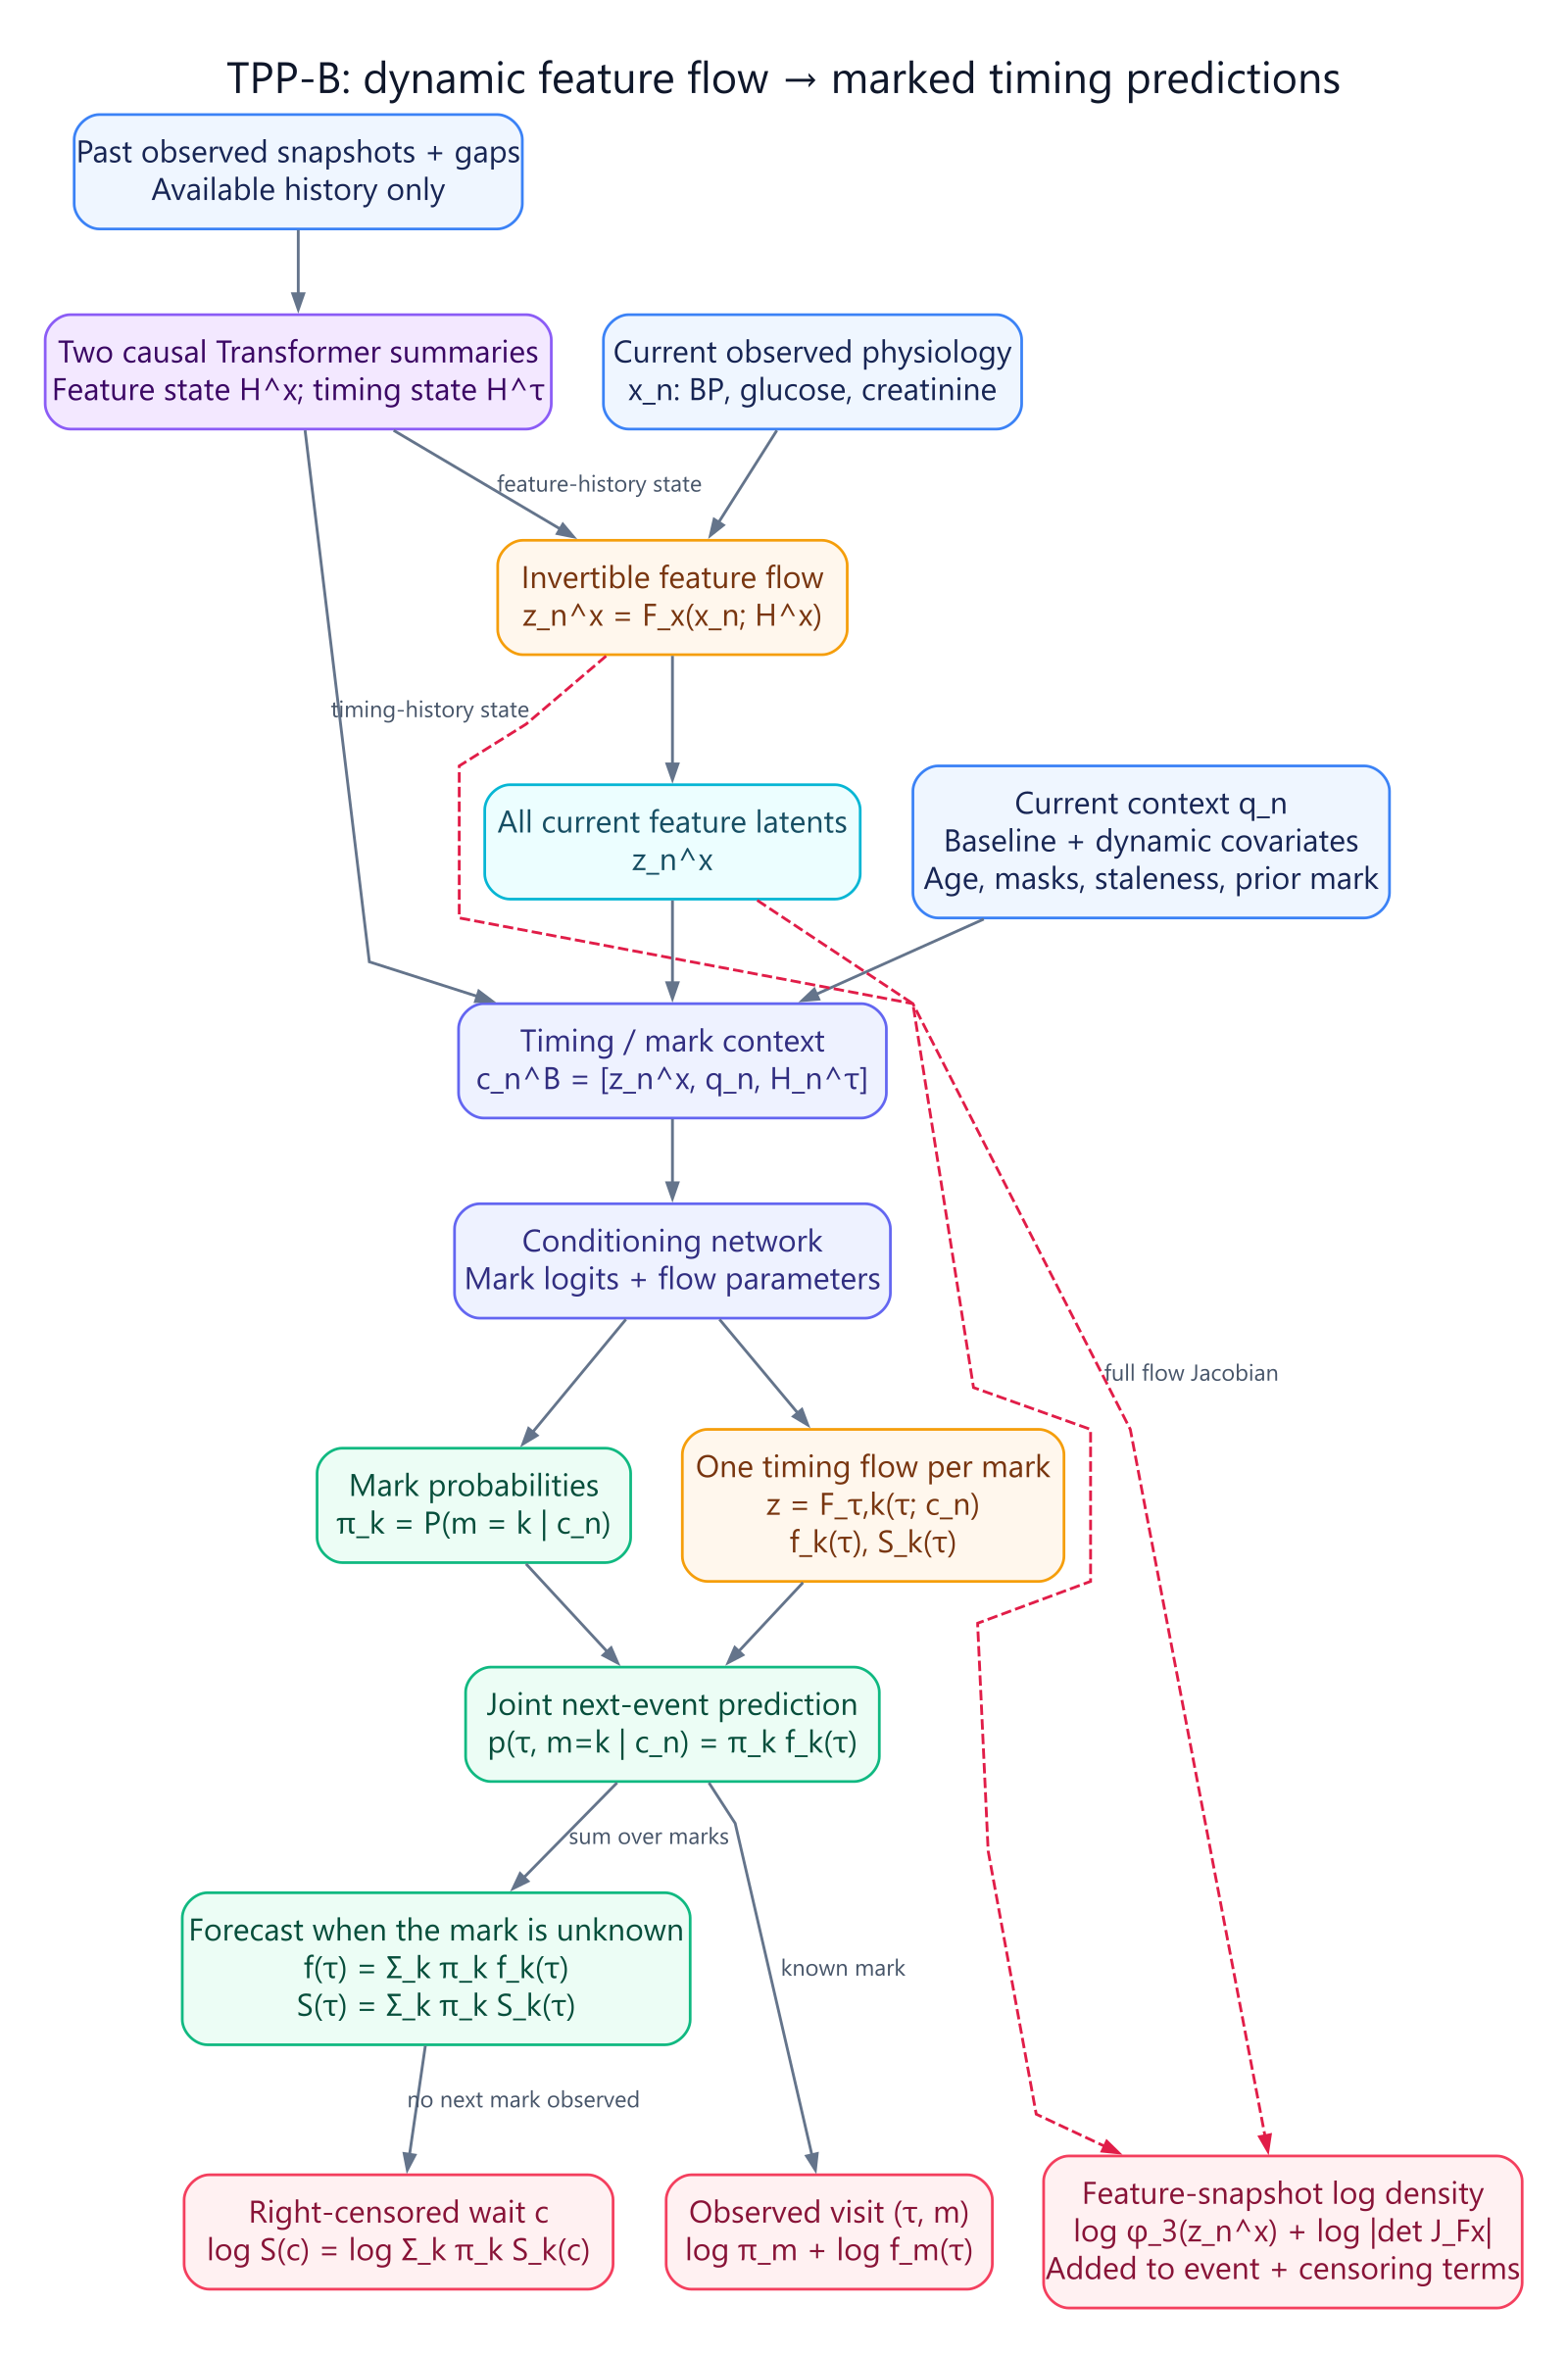

In [6]:
from IPython.display import display
import base64
# TPP-B: inputs → outputs
display({
    'image/svg+xml': (ROOT / 'diagrams/tpp_b.svg').read_text(encoding='utf-8'),
    'image/png': base64.b64encode((ROOT / 'diagrams/tpp_b.png').read_bytes()).decode('ascii'),
}, raw=True)

We now fit TPP-B and inspect the joint NLL, which combines event timing, event marks, right censoring and dynamic feature-snapshot density.

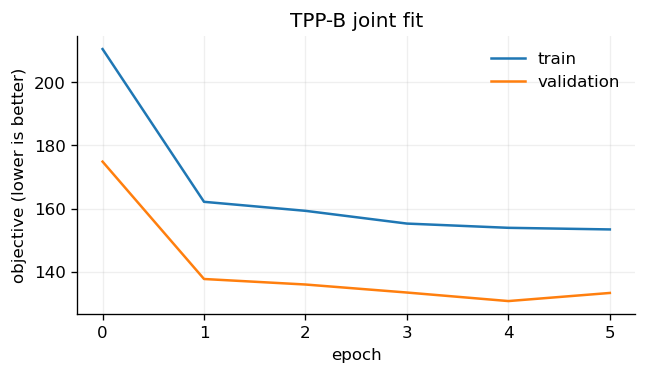

In [7]:
tpp_b=fit_tpp_b(dynamic_data,pre,epochs=EPOCHS,device=DEVICE)
fig,ax=plt.subplots(figsize=(6,3)); plot_fit_history(tpp_b,ax,title="TPP-B joint fit"); plt.show()

Let’s inspect TPP-B’s fitted intensity and next-event forecast, using its latest dynamic context.

We are now at the right-censoring time \(t=t_C\): no further visit has been observed since the last event at \(t_n\). Let \(a=t_C-t_n\) and let \(h>0\) be time into the future. Holding the latest available context \(c_n\) fixed, we condition on having already waited \(a\):

\[
p(T_{\mathrm{next}}-t_C=h,m=k\mid T_{\mathrm{next}}>t_C,c_n)
=\frac{\pi_k(c_n)f_k(a+h\mid c_n)}{\sum_j\pi_j(c_n)S_j(a\mid c_n)}.
\]

The coloured density curves show each event type's contribution over future time; integrating a curve up to a horizon gives the probability that the **next** event has that type and occurs before that horizon. The black curve sums the types. Survival gives the probability of no next event yet, and the marked intensity curves give the instantaneous rate for each type among patients still waiting. These are next-event forecasts, rather than probabilities of every event in a simulated future trajectory.

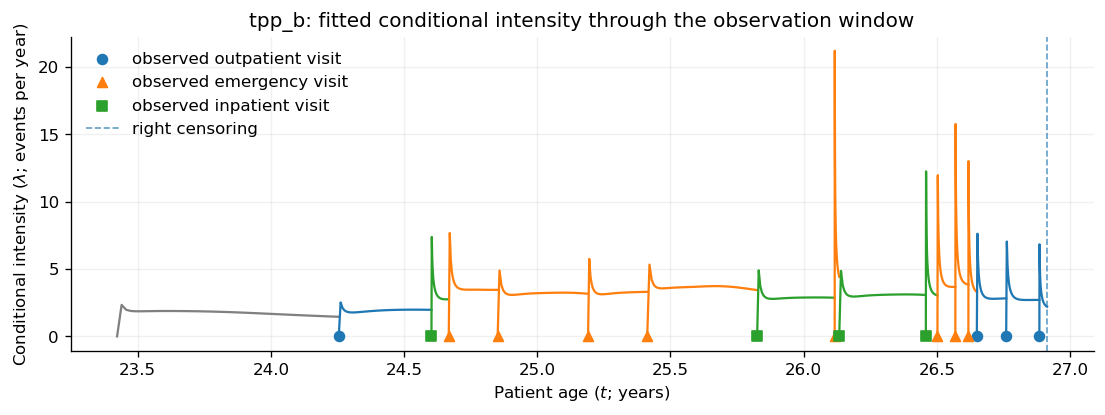

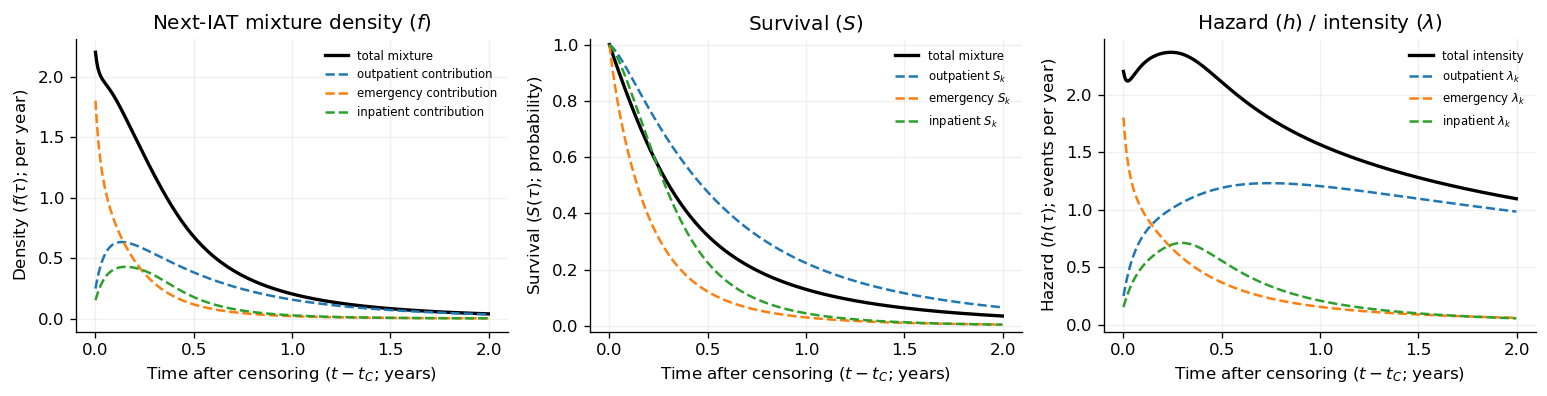

In [8]:
seq_b=representative_tpp_sequence(dynamic_data["test"],min_events=6)
fig,ax=plt.subplots(figsize=(11,3.4)); plot_tpp_timeline_fit(tpp_b,seq_b,pre,ax=ax); plt.show()
plot_next_event_forecast(tpp_b,seq_b,pre,horizon_days=730); plt.show()

Let’s inspect the dynamic feature distributions at the observed visit origins. For each snapshot, the feature flow uses earlier snapshots to generate standard-normal latent draws and maps them back through its inverse into blood pressure, glucose and creatinine. The shaded bands cover the central 80% of draws and the line shows the median; points show the feature states used by the TPP and crosses show raw irregular measurements. This is a sequence of one-step predictions conditional on observed history, rather than an open-loop forecast from censoring.

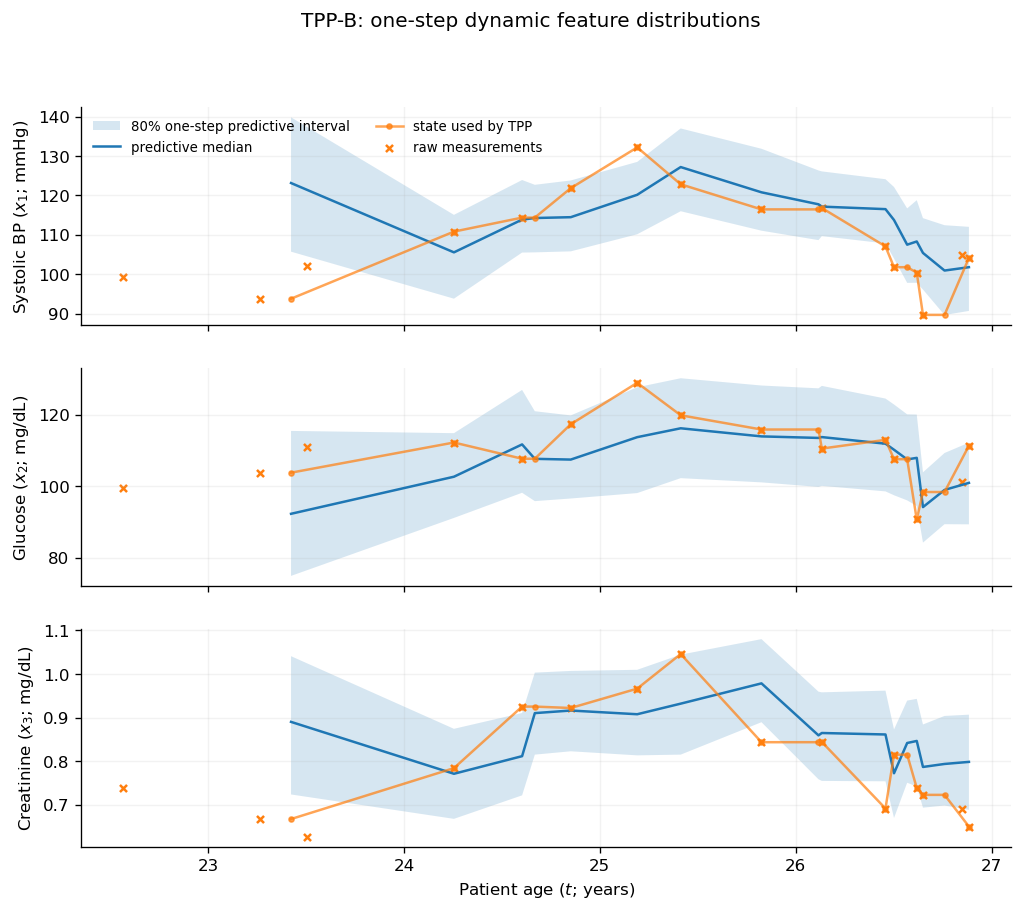

In [9]:
plot_feature_flow_fit(tpp_b,seq_b,pre,dataset,seq_b.patient_id,n_samples=350,title="TPP-B: one-step dynamic feature distributions"); plt.show()

Starting at \(t_C\), we now sample the remaining waiting time conditional on no event through \(t_C\), using the mark-conditioned timing mixture. We append the latest observed snapshot to the feature history, draw a fresh standard-normal feature latent, and invert the feature flow to obtain a next-visit snapshot. Histograms show the remaining wait and the marginal predictive distributions of each feature in clinical units.

In this implementation, the feature flow depends on snapshot history, but does **not** directly condition on the sampled future wait or event mark. Thus these feature histograms describe the next snapshot, not a continuously evolving feature trajectory or an event-type-specific feature forecast. No unobserved measurements after \(t_C\) are supplied.

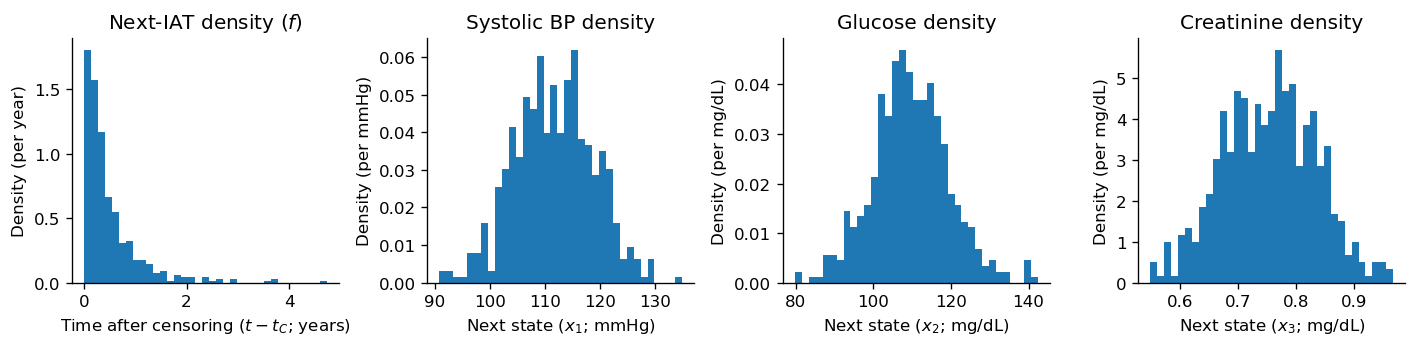

In [10]:
waits,feature_draws=forecast_next_feature_snapshot(tpp_b,seq_b,pre,n_samples=500,seed=9)
fig,axes=plt.subplots(1,4,figsize=(12,3))
axes[0].hist(waits/365.2425,bins=35,density=True); axes[0].set(title=r"Next-IAT density ($f$)",xlabel=r"Time after censoring ($t-t_C$; years)",ylabel="Density (per year)")
for d,(ax,v) in enumerate(zip(axes[1:],VARIABLES),start=1):
    ax.hist(feature_draws[v],bins=35,density=True); 
    name,unit={"systolic_bp":("Systolic BP","mmHg"),"glucose":("Glucose","mg/dL"),"creatinine":("Creatinine","mg/dL")}[v]
    ax.set(title=f"{name} density",xlabel=f"Next state ($x_{d}$; {unit})",ylabel=f"Density (per {unit})")
plt.tight_layout(); plt.show()

TPP-B can therefore generate future feature **snapshots** autoregressively. This is not the same object as a GP trajectory: it does not directly define a smooth function \(x_d(t)\) at every age.

## TPP-C — shared/private latent state

TPP-C keeps the feature transform invertible but partitions it:

\[
F_x(x_n)=(u_n,r_n).
\]

The timing branch is restricted to the shared coordinates

\[
p(\tau_{n+1}\mid x_n)=p(\tau_{n+1}\mid u_n),
\]

while \(r_n\) preserves feature information needed for invertibility. The hypothesis is that \(u_n\) is a compact feature state relevant to event timing.
The shared context predicts mark probabilities and a mark-specific timing flow. The marginal timing prediction still sums over marks; the private coordinates do not enter either current prediction head directly.


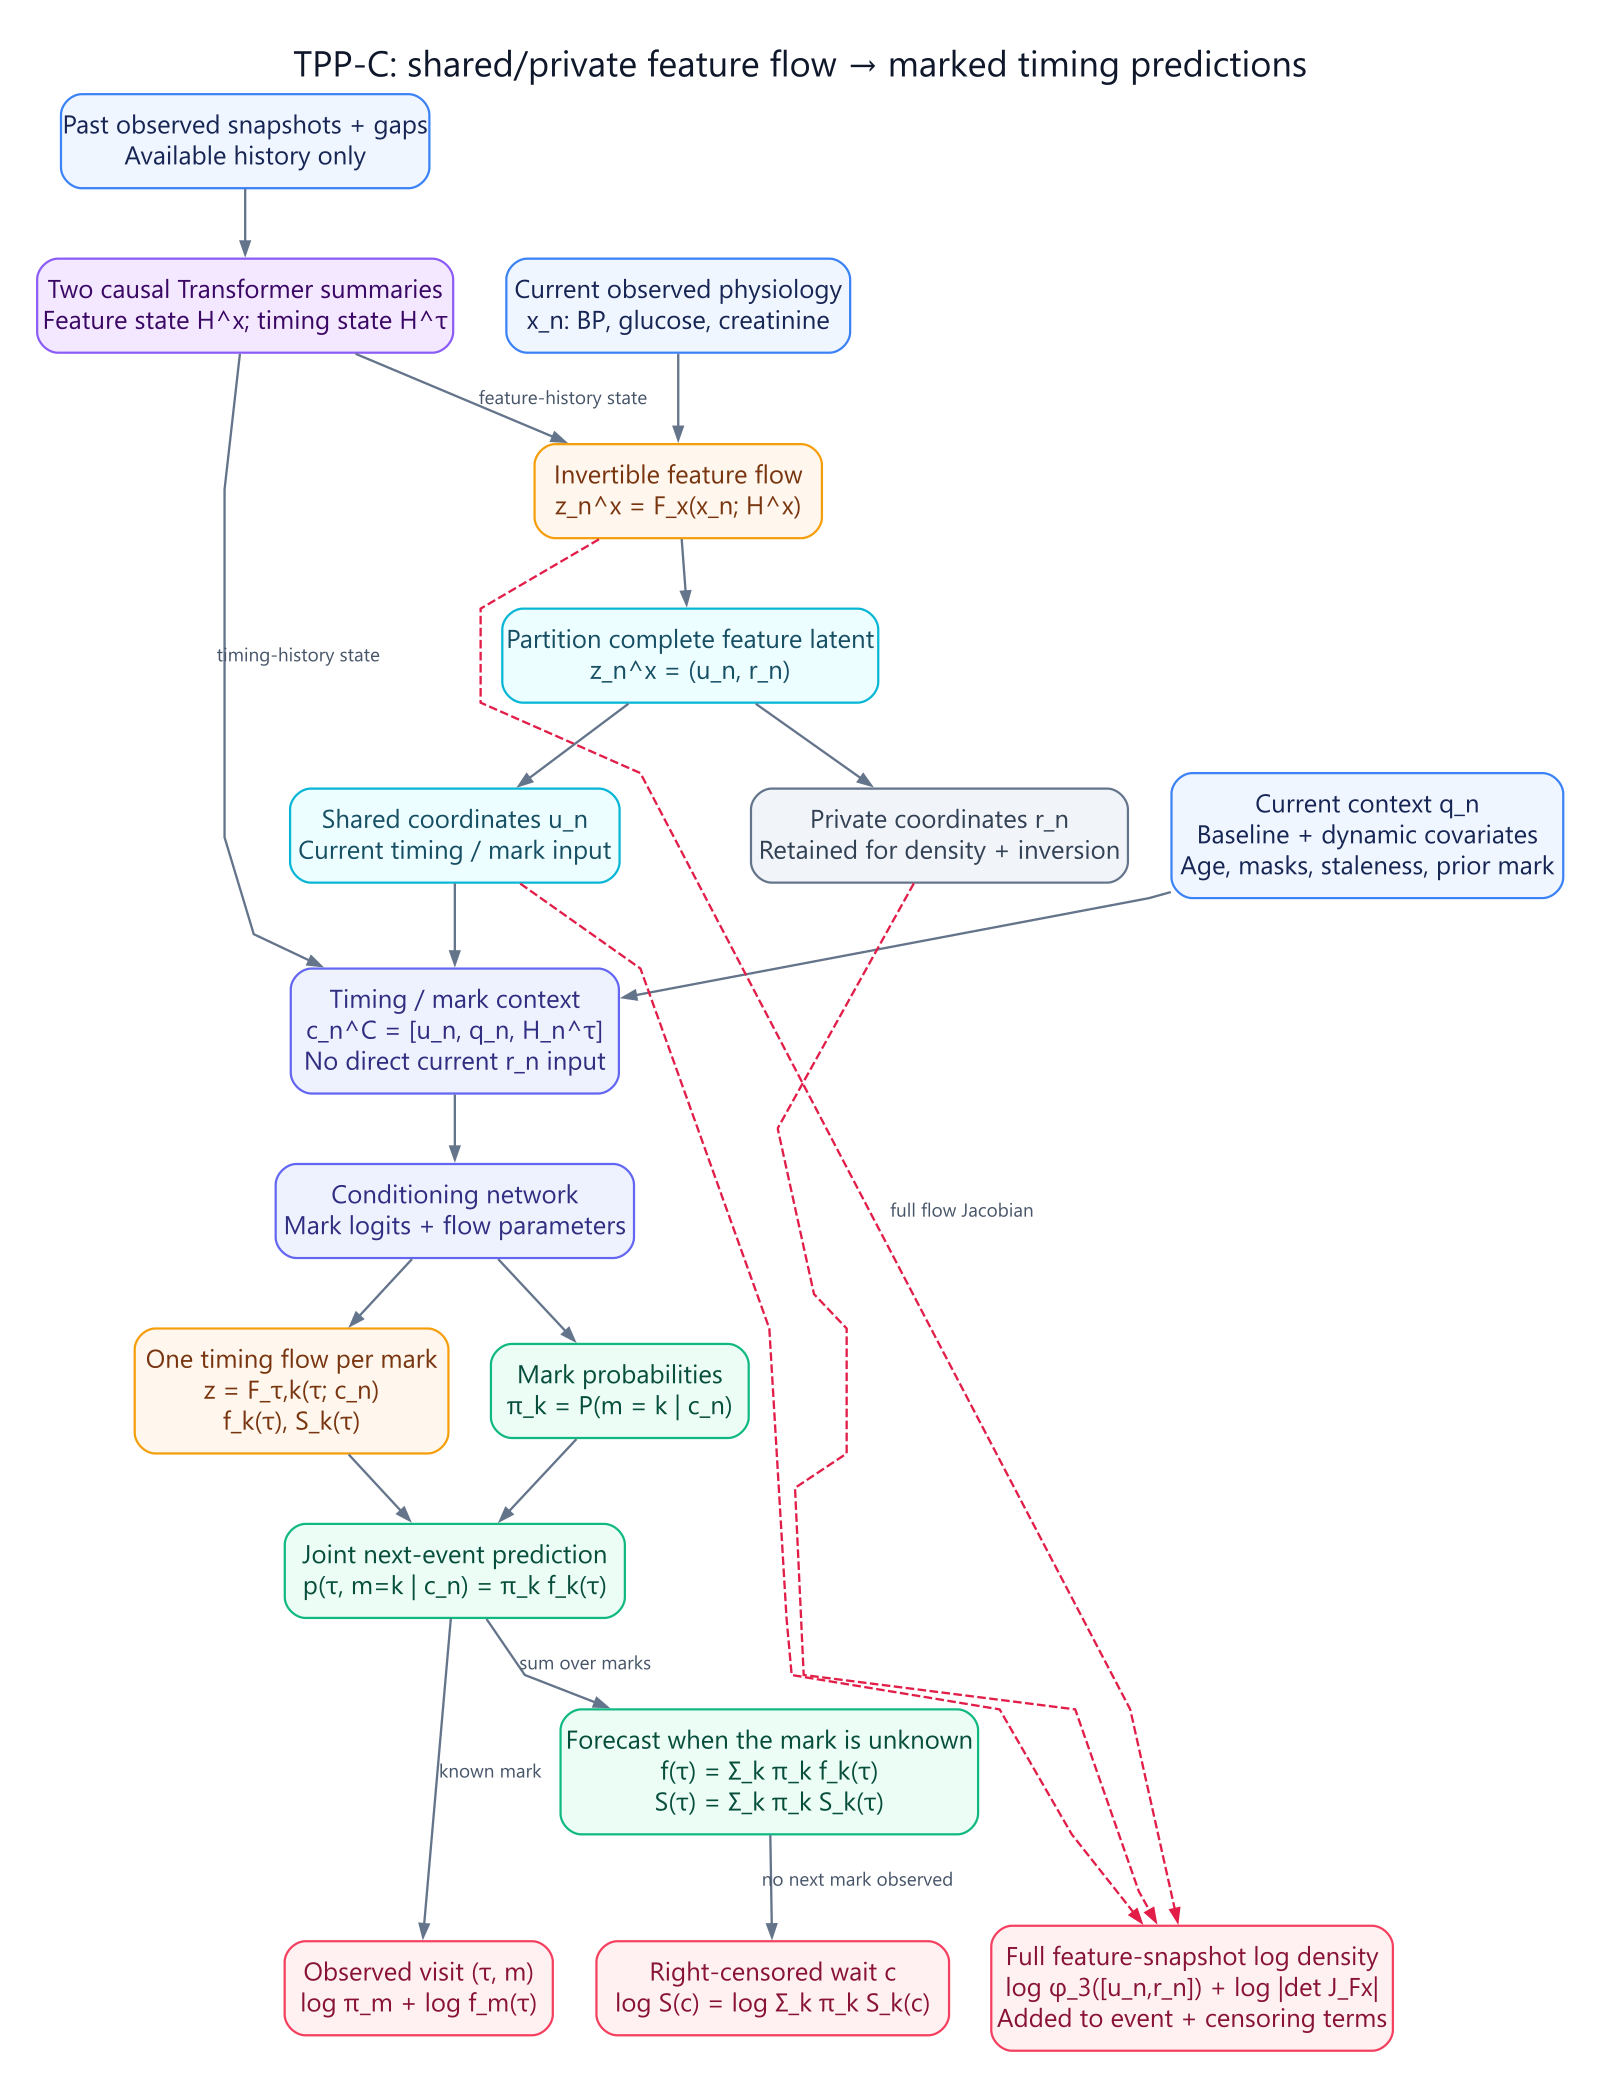

In [11]:
from IPython.display import display
import base64
# TPP-C: inputs → outputs
display({
    'image/svg+xml': (ROOT / 'diagrams/tpp_c.svg').read_text(encoding='utf-8'),
    'image/png': base64.b64encode((ROOT / 'diagrams/tpp_c.png').read_bytes()).decode('ascii'),
}, raw=True)

We now fit TPP-C and inspect its joint NLL. The feature flow models the full snapshot, while only its current shared latent coordinates feed the timing and mark heads directly.

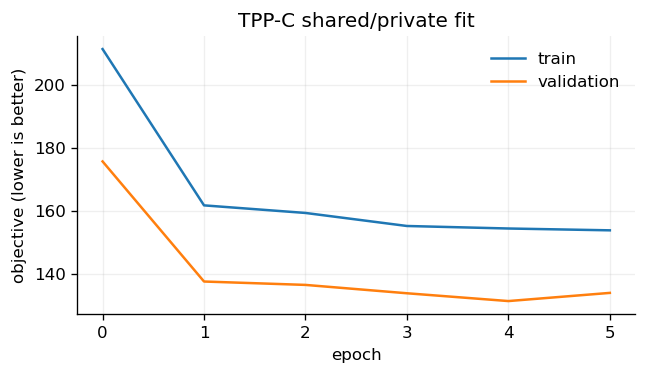

In [12]:
tpp_c=fit_tpp_c(dynamic_data,pre,epochs=EPOCHS,device=DEVICE)
fig,ax=plt.subplots(figsize=(6,3)); plot_fit_history(tpp_c,ax,title="TPP-C shared/private fit"); plt.show()

Let’s inspect TPP-C’s fitted intensity and next-event forecast.

We are now at the right-censoring time \(t=t_C\): no further visit has been observed since the last event at \(t_n\). Let \(a=t_C-t_n\) and let \(h>0\) be time into the future. Holding the latest available context \(c_n\) fixed, we condition on having already waited \(a\):

\[
p(T_{\mathrm{next}}-t_C=h,m=k\mid T_{\mathrm{next}}>t_C,c_n)
=\frac{\pi_k(c_n)f_k(a+h\mid c_n)}{\sum_j\pi_j(c_n)S_j(a\mid c_n)}.
\]

The coloured density curves show each event type's contribution over future time; integrating a curve up to a horizon gives the probability that the **next** event has that type and occurs before that horizon. The black curve sums the types. Survival gives the probability of no next event yet, and the marked intensity curves give the instantaneous rate for each type among patients still waiting. These are next-event forecasts, rather than probabilities of every event in a simulated future trajectory.

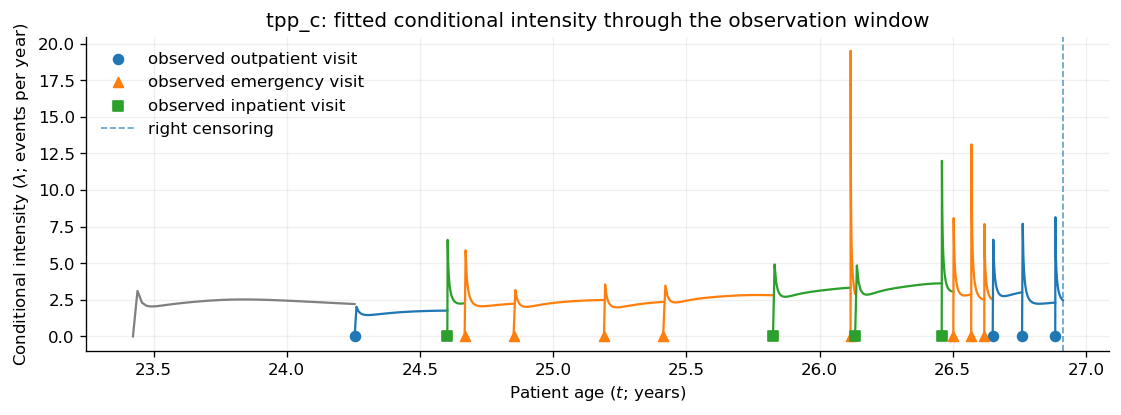

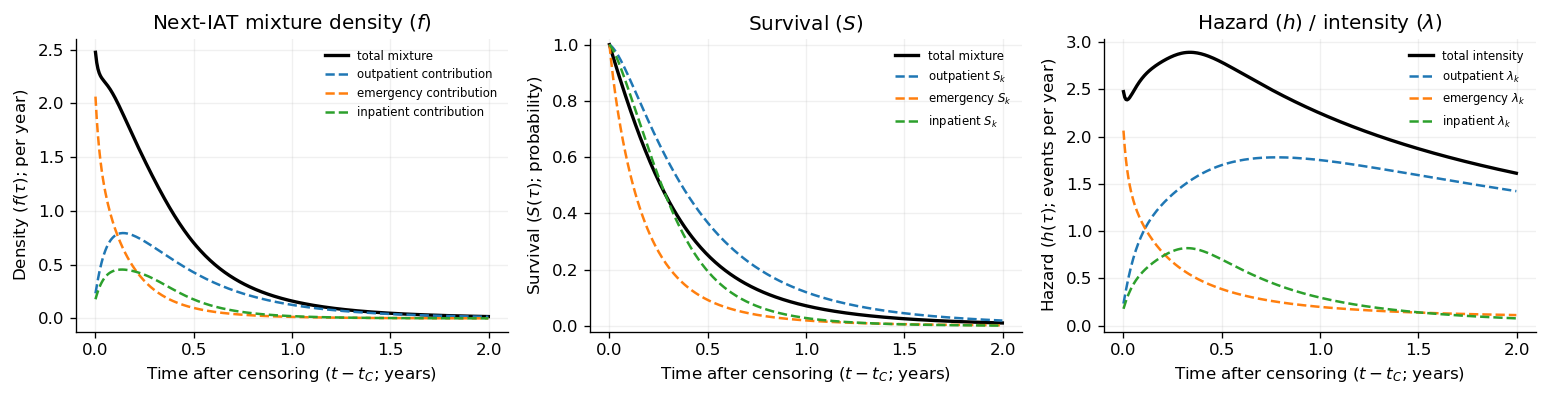

In [13]:
seq_c=representative_tpp_sequence(dynamic_data["test"],min_events=6)
fig,ax=plt.subplots(figsize=(11,3.4)); plot_tpp_timeline_fit(tpp_c,seq_c,pre,ax=ax); plt.show()
plot_next_event_forecast(tpp_c,seq_c,pre,horizon_days=730); plt.show()

Let’s inspect the dynamic feature distributions at the observed visit origins. For each snapshot, the feature flow uses earlier snapshots to generate standard-normal latent draws and maps them back through its inverse into blood pressure, glucose and creatinine. The shaded bands cover the central 80% of draws and the line shows the median; points show the feature states used by the TPP and crosses show raw irregular measurements. This is a sequence of one-step predictions conditional on observed history, rather than an open-loop forecast from censoring.

TPP-C uses the full shared/private latent vector when generating these snapshots.

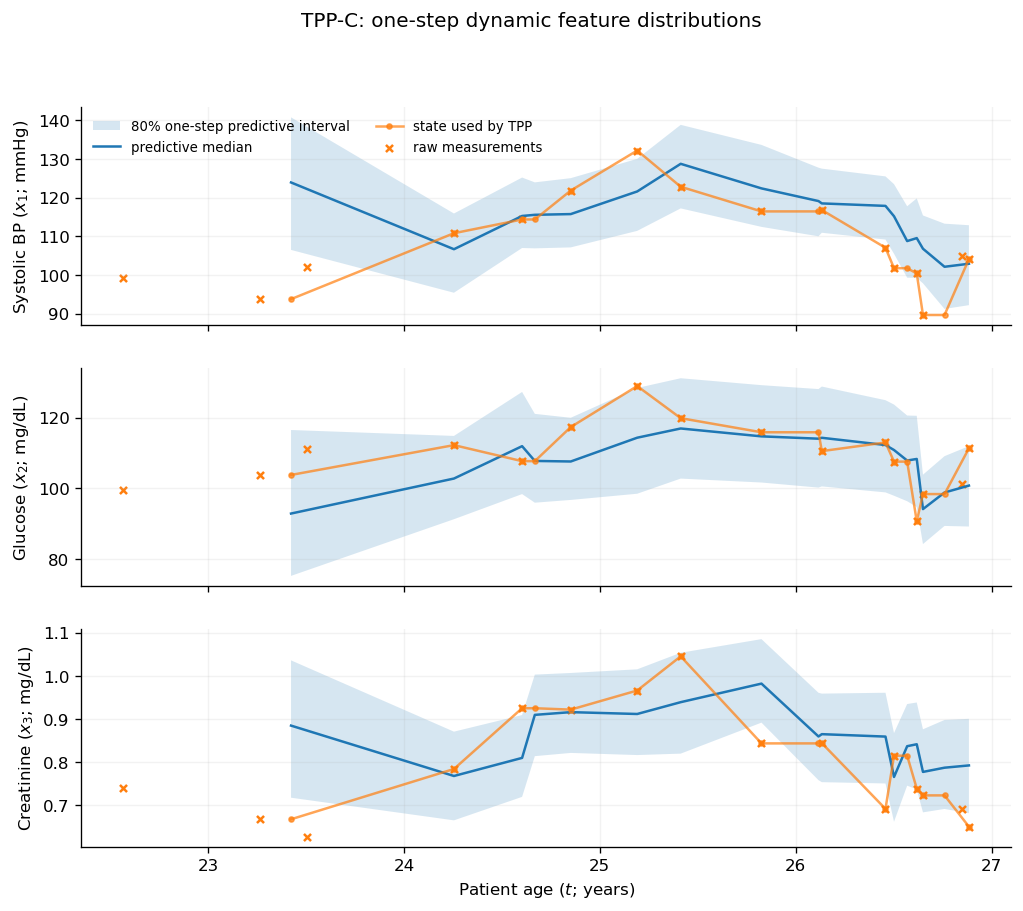

In [14]:
plot_feature_flow_fit(tpp_c,seq_c,pre,dataset,seq_c.patient_id,n_samples=350,title="TPP-C: one-step dynamic feature distributions"); plt.show()

### Constructing \((u,r)\) at inference time

For an observed current feature state, no variational encoder is required. The feature flow is invertible, so we transform the observed state exactly:

\[
z_x=F_x(x_t;H_{t^-}),\qquad z_x=(u_t,r_t).
\]

The next-event distribution uses \(u_t\). If we want to reconstruct the full observed state, both \(u_t\) and \(r_t\) are required.

We now transform the latest observed physiology snapshot into shared coordinates \(u\) and private coordinates \(r\). Both contribute to feature density and reconstruction; only current \(u\) enters the timing and mark context directly.

In [15]:
j=len(seq_c.contexts)-1
past=_dynamic_history(seq_c,j)
u,r=tpp_c.split_latents(seq_c.contexts[-1],history=past)
pd.DataFrame({"latent": [f"u[{i}]" for i in range(len(u))]+[f"r[{i}]" for i in range(len(r))],
              "value": np.r_[u.detach().cpu().numpy(),r.detach().cpu().numpy()]})

,latent,value
0,u[0],-0.061593
1,u[1],1.517756
2,r[0],-2.033833


Starting at \(t_C\), we now sample the remaining waiting time conditional on no event through \(t_C\), using the mark-conditioned timing mixture. We append the latest observed snapshot to the feature history, draw a fresh standard-normal feature latent, and invert the feature flow to obtain a next-visit snapshot. Histograms show the remaining wait and the marginal predictive distributions of each feature in clinical units.

In this implementation, the feature flow depends on snapshot history, but does **not** directly condition on the sampled future wait or event mark. Thus these feature histograms describe the next snapshot, not a continuously evolving feature trajectory or an event-type-specific feature forecast. No unobserved measurements after \(t_C\) are supplied.

For TPP-C, next-snapshot generation draws both shared and private latent coordinates and inverts the complete feature flow.

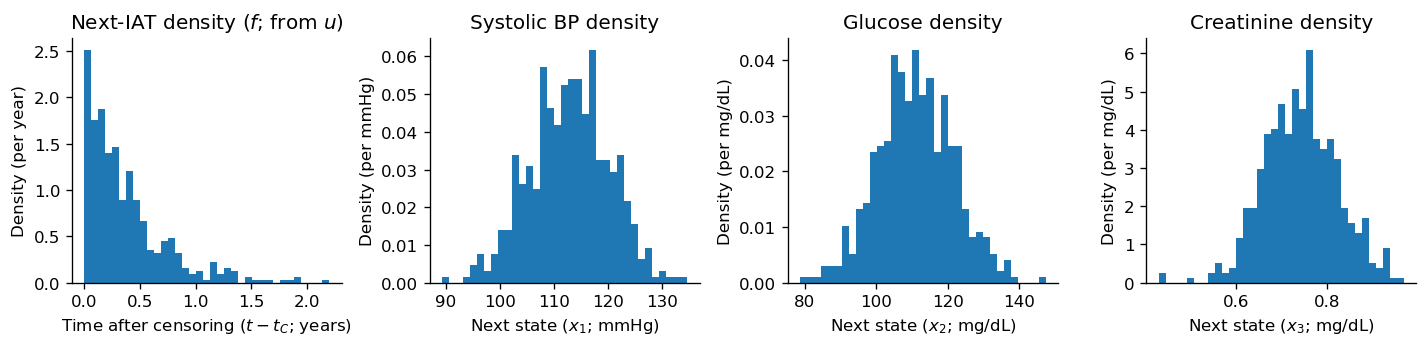

In [16]:
waits,feature_draws=forecast_next_feature_snapshot(tpp_c,seq_c,pre,n_samples=500,seed=13)
fig,axes=plt.subplots(1,4,figsize=(12,3))
axes[0].hist(waits/365.2425,bins=35,density=True); axes[0].set(title=r"Next-IAT density ($f$; from $u$)",xlabel=r"Time after censoring ($t-t_C$; years)",ylabel="Density (per year)")
for d,(ax,v) in enumerate(zip(axes[1:],VARIABLES),start=1):
    ax.hist(feature_draws[v],bins=35,density=True); 
    name,unit={"systolic_bp":("Systolic BP","mmHg"),"glucose":("Glucose","mg/dL"),"creatinine":("Creatinine","mg/dL")}[v]
    ax.set(title=f"{name} density",xlabel=f"Next state ($x_{d}$; {unit})",ylabel=f"Density (per {unit})")
plt.tight_layout(); plt.show()

## What the three TPPs infer

| Model | Primary predictive object | Additional feature inference |
|---|---|---|
| TPP-A | \(p(\tau_{next}\mid H_t)\) | none |
| TPP-B | \(p(\tau_{next}\mid H_t,x_t)\) | dynamic feature-state generation \(p(x_{next}\mid\text{past})\) |
| TPP-C | \(p(\tau_{next}\mid u_t)\) | feature generation plus an explicit shared/private latent decomposition |

The TPP branch is the natural component for **when something happens**. The following notebooks use GPs for the different question: **what is the continuous physiological trajectory between and beyond irregular measurements?**

## What these feature forecasts leave unanswered

TPP-A predicts event times and marks but does not generate physiology. TPP-B/C additionally generate the next physiological snapshot:

\[
p(x_{\mathrm{next}}\mid\text{observed snapshot history}).
\]

### Recap: how a complete future is generated

For TPP-B/C, sampling a complete future means generating an event and then a snapshot at that event's time:

1. **Sample the next mark** \(m_{n+1}\) from its context-dependent probabilities.
2. **Sample the IAT** \(\tau_{n+1}\) from the timing flow conditional on that mark, then advance to \(t_{n+1}=t_n+\tau_{n+1}\).
3. **Generate the feature snapshot** \(x_{n+1}\) by drawing normal feature latents and inverting the feature flow conditional on snapshot history.
4. **Append the generated snapshot and gap to history**, then repeat to generate subsequent events and states.

At censoring, we have already waited \(a=t_C-t_n\) without an event. For the first generated event, we use the survival-updated mark probabilities \(w_k(a)\), draw that mark's IAT conditional on exceeding \(a\), and advance from \(t_C\) by the remaining wait. Later steps start at their newly generated event origins.

**Placed at that time does not mean conditioned on that time.** In the current implementation, the feature flow uses snapshot history but does not directly take the sampled next-event mark or IAT as conditioning inputs. Those draws determine when and which event occurs; they do not directly shape the new feature distribution. Other dynamic metadata is carried forward during simulation.

A next-snapshot histogram shows alternative feature draws across possible futures. It does not mean all those sampled snapshots occur in one patient's timeline. A complete rollout instead creates one ordered sequence of event times, marks and snapshots.

We can repeat this operation autoregressively: sample the next event time and mark, generate its feature snapshot, append the generated state to the history, and continue. Below, coloured points show several such futures from the censoring time \(t_C\). **Thin connectors with “?” mark the unspecified path between snapshots:** they are visual guides, not modelled physiological trajectories. The model generates snapshots at event times without specifying how physiology evolves between those times. The right-hand histograms show next-snapshot marginals for the same example feature, systolic BP; earlier plots show the other features.

Now ask: **what is this patient's blood-pressure distribution exactly one year after \(t_C\), whether or not a visit occurs then?** The vertical dotted line marks that query. The next-snapshot histogram does not answer it: its target is the next snapshot, whose event time is random. Likewise, drawing lines between sampled points would add an interpolation rule that was not learned by these models.

These forecasts are useful for next-visit simulation, but are **not sufficient for arbitrary-time physiological interpolation and uncertainty between sparse measurements**. This is a limitation of the modelled object, not evidence that a broad or irregular snapshot distribution is necessarily a bad fit. In the current implementation, snapshot generation also does not directly condition on the sampled next-event mark or waiting time; other dynamic metadata is carried forward during simulation.

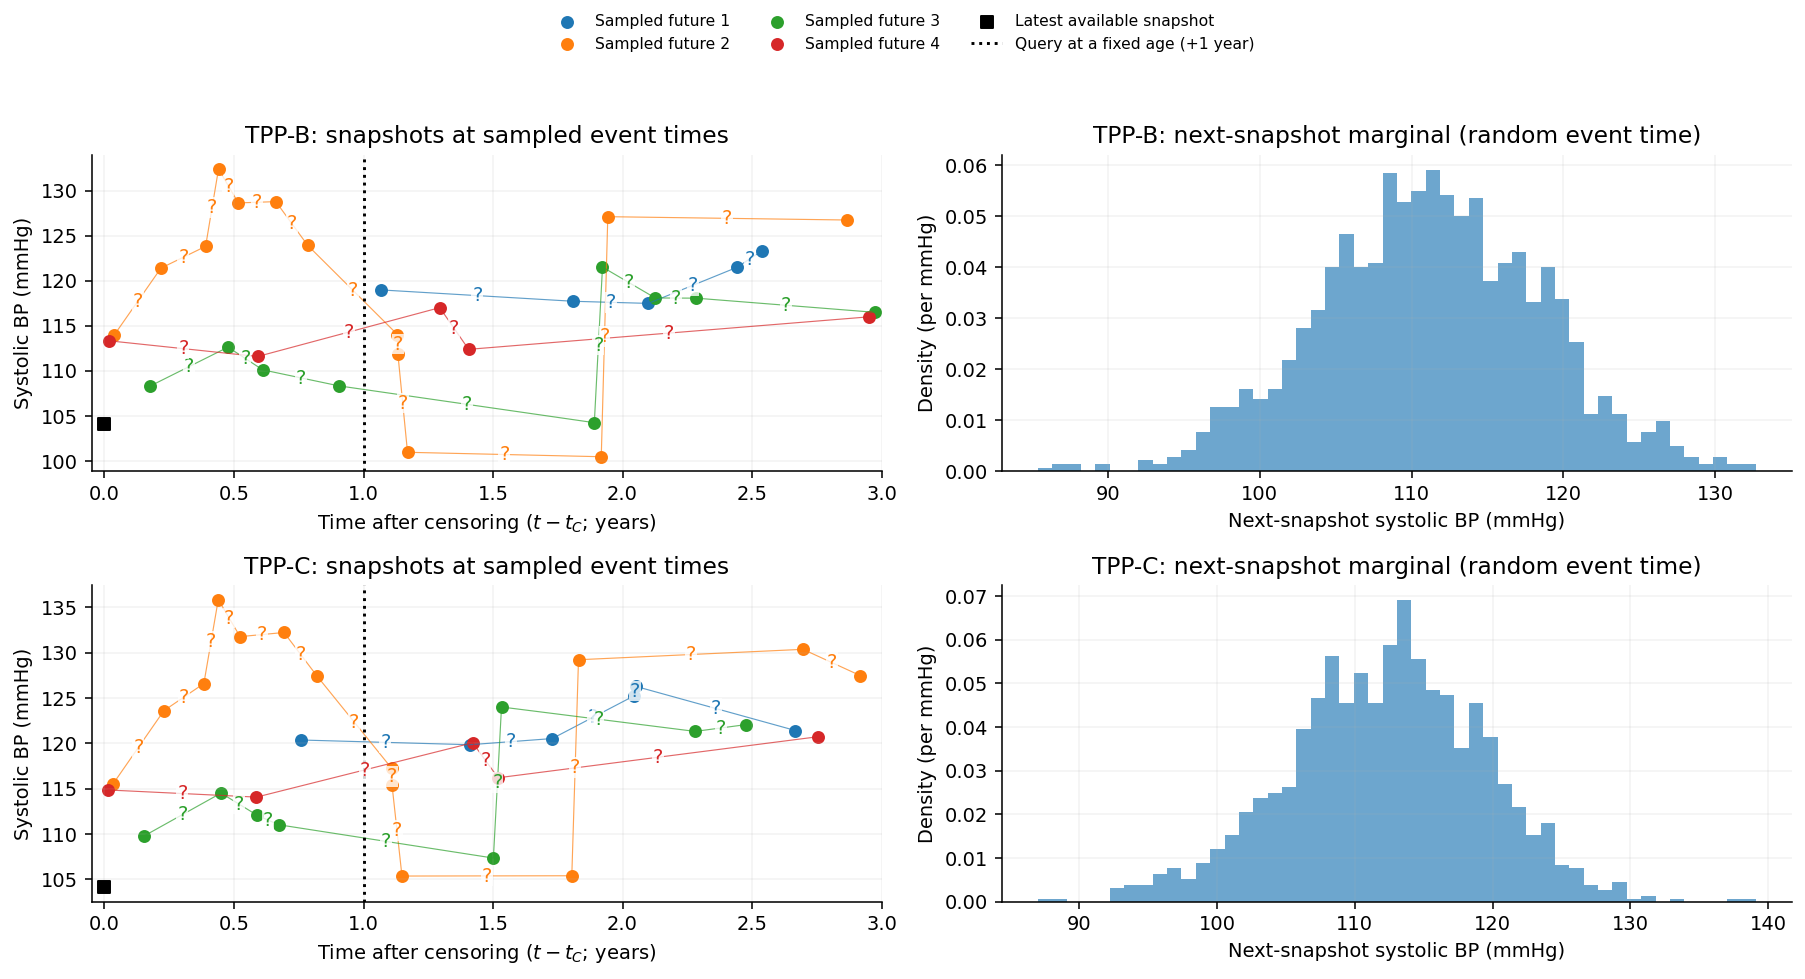

In [17]:
# Show next-snapshot marginals alongside event-indexed sampled futures.
fig,axes=plt.subplots(2,2,figsize=(13,7),dpi=140)
bp_index=physiology_feature_indices(pre)[0]
bp_mu,bp_sd=pre.measurement_scales["systolic_bp"]
for row,(name,model,seq) in enumerate([("TPP-B",tpp_b,seq_b),("TPP-C",tpp_c,seq_c)]):
    left,right=axes[row]
    past=_dynamic_history(seq,len(seq.contexts)-1)
    elapsed=float(seq.end-(seq.times[-1] if len(seq.times) else 0.))
    for draw in range(4):
        generated=model.simulate_timeline(seq.contexts[-1],end_days=seq.end+3*365.2425,
                                         history=past,current_time=seq.end,elapsed_days=elapsed,
                                         seed=130+draw,max_events=1000)
        points=generated["features"][1:]
        if len(points):
            times=(generated["times"]-seq.end)/365.2425
            values=bp_mu+bp_sd*points[:,bp_index]
            dots=left.scatter(times,values,s=32,label=f"Sampled future {draw+1}")
            colour=dots.get_facecolor()[0]
            # Connectors illustrate the missing path, not modelled interpolation.
            left.plot(times,values,color=colour,linewidth=.6,alpha=.7)
            for j in range(len(times)-1):
                left.text((times[j]+times[j+1])/2,(values[j]+values[j+1])/2,"?",
                          color=colour,ha="center",va="center",fontsize=10,zorder=5,
                          bbox=dict(facecolor="white",edgecolor="none",alpha=.8,pad=.4))
    left.scatter([0],[bp_mu+bp_sd*seq.contexts[-1,bp_index]],color="black",marker="s",
                 label="Latest available snapshot",zorder=4)
    left.axvline(1,color="black",linestyle=":",linewidth=1.5,label="Query at a fixed age (+1 year)")
    left.set(xlim=(-.05,3),title=f"{name}: snapshots at sampled event times",
             xlabel=r"Time after censoring ($t-t_C$; years)",ylabel="Systolic BP (mmHg)")
    _,next_features=forecast_next_feature_snapshot(model,seq,pre,n_samples=1500,seed=155+row)
    right.hist(next_features["systolic_bp"],bins=50,density=True,color="tab:blue",alpha=.65)
    right.set(title=f"{name}: next-snapshot marginal (random event time)",
              xlabel="Next-snapshot systolic BP (mmHg)",ylabel="Density (per mmHg)")
    for ax in (left,right): ax.grid(alpha=.15)
handles,labels=axes[0,0].get_legend_handles_labels()
fig.legend(handles,labels,loc="upper center",ncol=3,frameon=False,fontsize=8)
plt.tight_layout(rect=(0,0,1,.9)); plt.show()


## Comparing NLL on the same targets

A lower NLL means greater probability density assigned to the evaluation data. Scores are comparable only when they use the **same patients, observation windows, targets, units and averaging convention**.

We compare **TPP-B and TPP-C on the identical dynamic test sequences**. The first column evaluates timing, marks and censoring conditional on the available feature snapshots, excluding feature-density terms. The second evaluates the joint objective, including those same physiological snapshots. Compare B versus C **within a column**, rather than comparing the two columns: they score different targets. Both scores are averaged per patient sequence, in natural-log units (nats).

We exclude TPP-A from this numerical comparison: its static sequences can start earlier, before the first complete physiological snapshot used by B/C. Its training NLL also lacks their feature-density terms. A fair three-way timing comparison would require rebuilding all evaluation sequences on a shared window; subtracting feature terms alone would not fix the window mismatch. These short demonstration fits illustrate evaluation, rather than establishing a definitive model ranking.

In [18]:
import torch
with torch.no_grad():
    tpp_nll_comparison = pd.DataFrame([
        {"Model": name,
         "Event/mark + censoring NLL (nats/sequence)": float(model.conditional_nll(dynamic_data["test"])),
         "Joint NLL incl. features (nats/sequence)": float(model.joint_nll(dynamic_data["test"]))}
        for name, model in [("TPP-B", tpp_b), ("TPP-C", tpp_c)]
    ]).set_index("Model")
display(tpp_nll_comparison)


,Event/mark + censoring NLL (nats/sequence),Joint NLL incl. features (nats/sequence)
Model,,
TPP-B,104.175437,148.199703
TPP-C,103.909377,148.215743
